In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Pandas: 2.2.3
NumPy: 2.1.3


In [2]:
from tensorflow.keras.datasets import imdb

# Cargar el dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

print("Cantidad de reseñas de entrenamiento:", len(X_train))
print("Cantidad de reseñas de prueba:", len(X_test))
print("Primeras etiquetas:", y_train[:10])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Cantidad de reseñas de entrenamiento: 25000
Cantidad de reseñas de prueba: 25000
Primeras etiquetas: [1 0 0 1 0 0 1 0 1 0]


In [3]:
# Análisis exploratorio del dataset

print("Forma de X_train:", X_train.shape)
print("Forma de y_train:", y_train.shape)

# Distribución de clases
print("\nDistribución de sentimientos:")
print(pd.Series(y_train).value_counts().sort_index())

# Longitud de las reseñas
longitudes = [len(reseña) for reseña in X_train]

print("\nLongitud mínima:", min(longitudes))
print("Longitud máxima:", max(longitudes))
print("Longitud promedio:", np.mean(longitudes))
print("Mediana:", np.median(longitudes))

Forma de X_train: (25000,)
Forma de y_train: (25000,)

Distribución de sentimientos:
0    12500
1    12500
Name: count, dtype: int64

Longitud mínima: 11
Longitud máxima: 2494
Longitud promedio: 238.71364
Mediana: 178.0


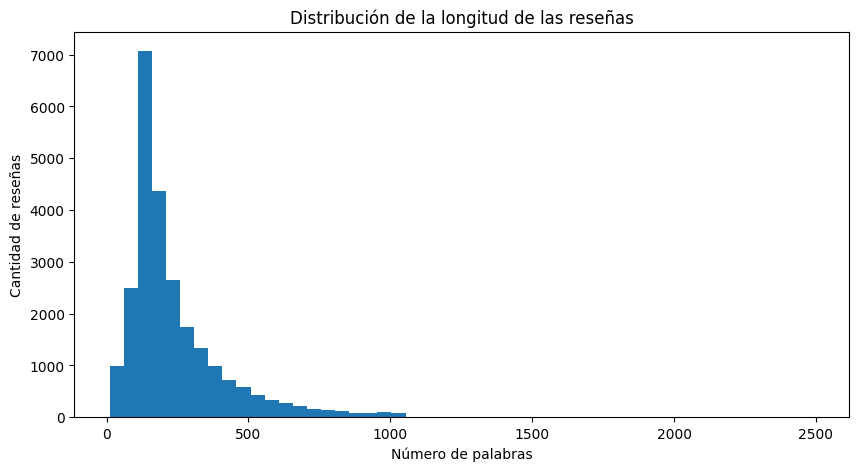

In [4]:
plt.figure(figsize=(10, 5))

plt.hist(longitudes, bins=50)

plt.title("Distribución de la longitud de las reseñas")
plt.xlabel("Número de palabras")
plt.ylabel("Cantidad de reseñas")

plt.show()


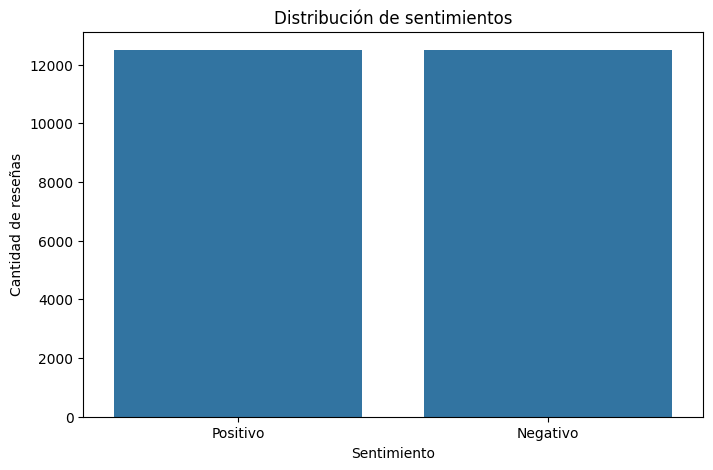

In [5]:
# Gráfica de distribución de sentimientos

sentimientos = pd.Series(y_train).map({
    0: "Negativo",
    1: "Positivo"
})

plt.figure(figsize=(8, 5))

sns.countplot(x=sentimientos)

plt.title("Distribución de sentimientos")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de reseñas")

plt.show()

In [6]:
# Obtener el diccionario palabra -> número
word_index = imdb.get_word_index()

# Crear diccionario número -> palabra
reverse_word_index = {value: key for key, value in word_index.items()}

def decodificar_reseña(secuencia):
    palabras = []

    for indice in secuencia:
        if indice >= 3:
            palabras.append(reverse_word_index.get(indice - 3, "?"))
        else:
            palabras.append("<especial>")

    return " ".join(palabras)


# Mostrar 5 reseñas de ejemplo
for i in range(5):
    print(f"\nReseña {i + 1}")
    print("Sentimiento:", "Positivo" if y_train[i] == 1 else "Negativo")
    print(decodificar_reseña(X_train[i])[:1000])
    print("-" * 80)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step

Reseña 1
Sentimiento: Positivo
<especial> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <especial> is an amazing actor and now the same being director <especial> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <especial> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <especial> to the two little boy's that played the <especial> of norman and paul they were just brilliant children are often left out of the <especial> list i think because the stars that play them a

In [7]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Longitud máxima de cada reseña
MAX_LEN = 200

# Aplicar padding
X_train_pad = pad_sequences(
    X_train,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Forma de X_train_pad:", X_train_pad.shape)
print("Forma de X_test_pad:", X_test_pad.shape)

Forma de X_train_pad: (25000, 200)
Forma de X_test_pad: (25000, 200)


In [8]:
from sklearn.model_selection import train_test_split

# Dividir el conjunto de entrenamiento
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_pad,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Entrenamiento:", X_train_final.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test_pad.shape)

print("\nEtiquetas de entrenamiento:", y_train_final.shape)
print("Etiquetas de validación:", y_val.shape)
print("Etiquetas de prueba:", y_test.shape)

Entrenamiento: (20000, 200)
Validación: (5000, 200)
Prueba: (25000, 200)

Etiquetas de entrenamiento: (20000,)
Etiquetas de validación: (5000,)
Etiquetas de prueba: (25000,)


In [9]:
from tensorflow import keras
from tensorflow.keras import layers

# Parámetros
VOCAB_SIZE = 10000
EMBEDDING_DIM = 64
LSTM_UNITS = 64

# Construcción del modelo
model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    layers.LSTM(LSTM_UNITS),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

# Compilar modelo
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Mostrar arquitectura
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Early Stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Entrenamiento
history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 86ms/step - accuracy: 0.5141 - loss: 0.6927 - val_accuracy: 0.5288 - val_loss: 0.6895
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 88ms/step - accuracy: 0.5616 - loss: 0.6751 - val_accuracy: 0.5420 - val_loss: 0.6813
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 87ms/step - accuracy: 0.6038 - loss: 0.6546 - val_accuracy: 0.5202 - val_loss: 0.6891
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.6697 - loss: 0.5968 - val_accuracy: 0.5222 - val_loss: 0.6906


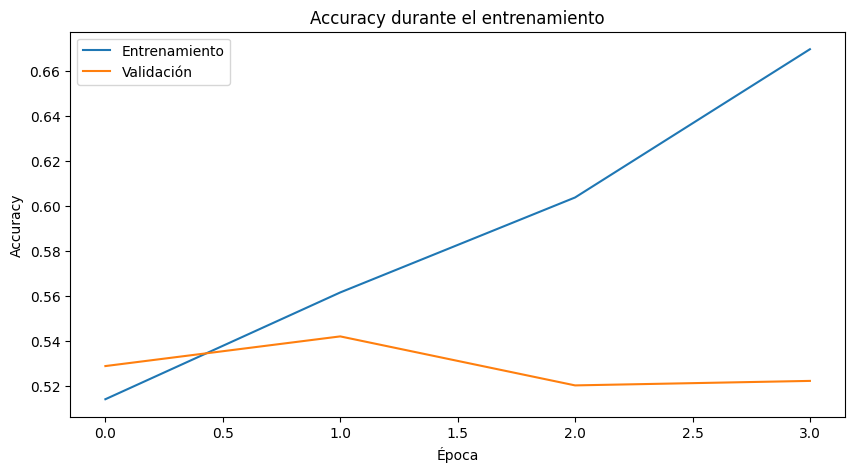

In [11]:
# Gráfica de accuracy

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")

plt.title("Accuracy durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

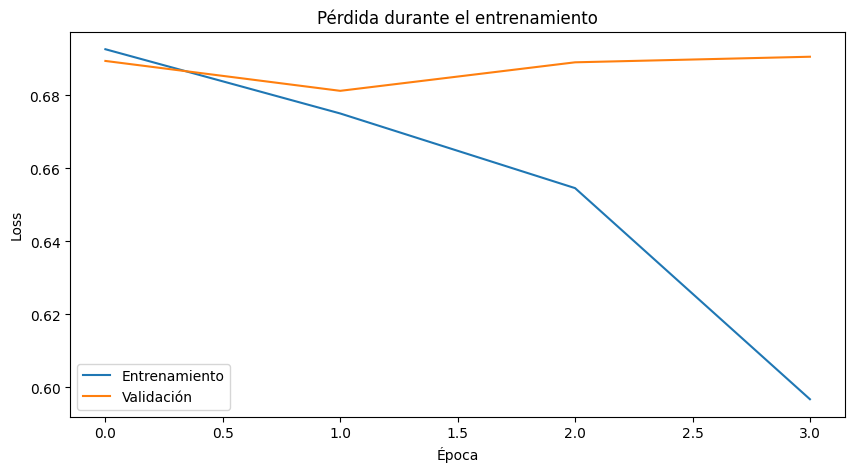

In [12]:
# Gráfica de pérdida

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")

plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [13]:
from tensorflow import keras
from tensorflow.keras import layers

# Crear una nueva arquitectura LSTM con mayor regularización
model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    layers.SpatialDropout1D(0.3),

    layers.LSTM(LSTM_UNITS),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 200, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 89ms/step - accuracy: 0.5122 - loss: 0.6949 - val_accuracy: 0.5160 - val_loss: 0.6893
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.5649 - loss: 0.6821 - val_accuracy: 0.5580 - val_loss: 0.6854
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 88ms/step - accuracy: 0.6032 - loss: 0.6482 - val_accuracy: 0.6182 - val_loss: 0.6289
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 89ms/step - accuracy: 0.6964 - loss: 0.5774 - val_accuracy: 0.7740 - val_loss: 0.5456
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - accuracy: 0.6712 - loss: 0.6046 - val_accuracy: 0.6024 - val_loss: 0.6604
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 88ms/step - accuracy: 0.6648 - loss: 0.6270 - val_accuracy: 0.6112 - val_loss: 0.6525


In [15]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("Pérdida en prueba:", test_loss)
print("Exactitud en prueba:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.7728 - loss: 0.5481
Pérdida en prueba: 0.5480618476867676
Exactitud en prueba: 0.7727599740028381


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Obtener probabilidades de predicción
y_pred_prob = model.predict(X_test_pad)

# Convertir probabilidades a clases 0/1
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negativo", "Positivo"]
))

782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step
Accuracy : 0.77276
Precision: 0.7639544785941008
Recall   : 0.78944
F1-score : 0.7764881772042334

Reporte de clasificación:
              precision    recall  f1-score   support

    Negativo       0.78      0.76      0.77     12500
    Positivo       0.76      0.79      0.78     12500

    accuracy                           0.77     25000
   macro avg       0.77      0.77      0.77     25000
weighted avg       0.77      0.77      0.77     25000



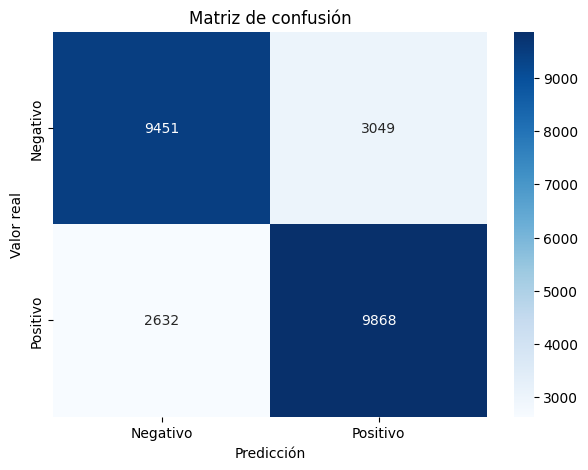

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negativo", "Positivo"],
    yticklabels=["Negativo", "Positivo"]
)

plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

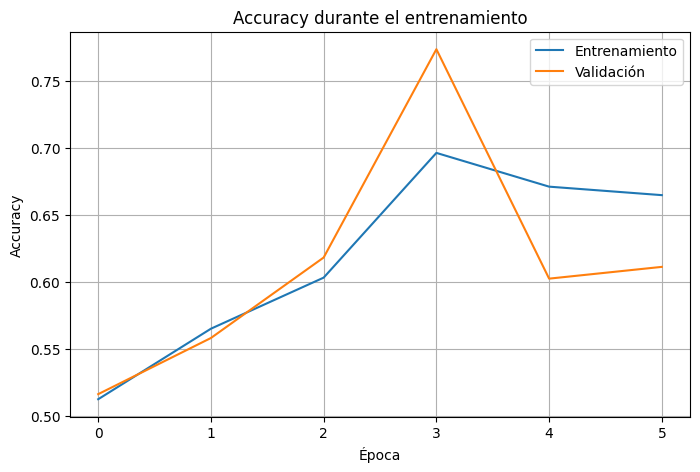

In [18]:
import matplotlib.pyplot as plt

# Obtener los valores registrados durante el entrenamiento
historia = history.history

# Gráfica de accuracy
plt.figure(figsize=(8, 5))
plt.plot(historia["accuracy"], label="Entrenamiento")
plt.plot(historia["val_accuracy"], label="Validación")

plt.title("Accuracy durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

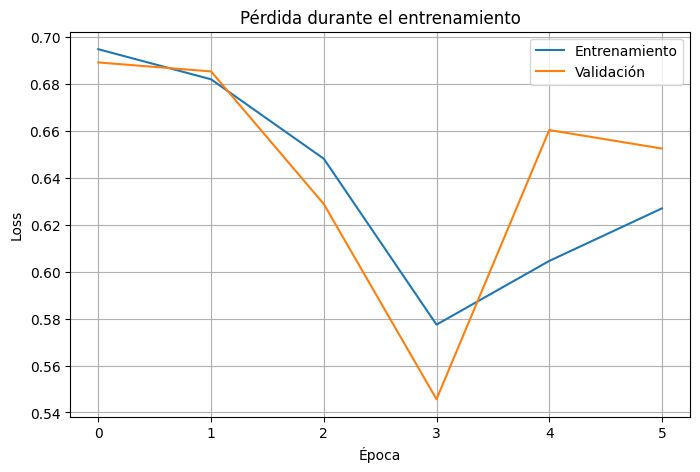

In [19]:
# Gráfica de loss
plt.figure(figsize=(8, 5))
plt.plot(historia["loss"], label="Entrenamiento")
plt.plot(historia["val_loss"], label="Validación")

plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [20]:
# ==========================================
# 10 PREDICCIONES DEL MODELO LSTM
# ==========================================

import numpy as np

# Seleccionar 10 reseñas del conjunto de prueba
indices = np.arange(10)

# Obtener probabilidades de predicción
predicciones_prob = model.predict(X_test_pad[indices], verbose=0)

print("=" * 100)
print("10 PREDICCIONES DEL MODELO LSTM")
print("=" * 100)

for i, indice in enumerate(indices):

    # Probabilidad predicha
    probabilidad = float(predicciones_prob[i][0])

    # Convertir a clase
    prediccion = 1 if probabilidad >= 0.5 else 0

    # Sentimientos
    sentimiento_real = "Positivo" if y_test[indice] == 1 else "Negativo"
    sentimiento_predicho = "Positivo" if prediccion == 1 else "Negativo"

    # Confianza de la predicción
    confianza = probabilidad if prediccion == 1 else 1 - probabilidad

    # Decodificar reseña
    reseña = decodificar_reseña(X_test[indice])

    print(f"\nRESEÑA {i + 1}")
    print("-" * 100)
    print("Texto:")
    print(reseña[:800])
    print("\nSentimiento real:", sentimiento_real)
    print("Predicción:", sentimiento_predicho)
    print(f"Confianza: {confianza * 100:.2f}%")
    print("Resultado:", "✓ CORRECTO" if sentimiento_real == sentimiento_predicho else "✗ INCORRECTO")

print("\n" + "=" * 100)

10 PREDICCIONES DEL MODELO LSTM

RESEÑA 1
----------------------------------------------------------------------------------------------------
Texto:
<especial> please give this one a miss br br <especial> <especial> and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could have allowed this one on his plate he almost seemed to know this wasn't going to work out and his performance was quite <especial> so all you madison fans give this a miss

Sentimiento real: Negativo
Predicción: Negativo
Confianza: 70.63%
Resultado: ✓ CORRECTO

RESEÑA 2
----------------------------------------------------------------------------------------------------
Texto:
<especial> this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the scenes take place on the same set in frances <especial> the sandy dennis character apartment but the film builds to a disturbing climax

In [21]:
# Guardar el modelo LSTM entrenado

import os

os.makedirs("models", exist_ok=True)

ruta_modelo = "models/modelo_sentimientos_lstm.keras"

model.save(ruta_modelo)

print("Modelo guardado correctamente en:")
print(ruta_modelo)

Modelo guardado correctamente en:
models/modelo_sentimientos_lstm.keras


In [22]:
# Guardar el vocabulario utilizado por el modelo

import json
import os

os.makedirs("models", exist_ok=True)

word_index = imdb.get_word_index()

with open("models/word_index.json", "w", encoding="utf-8") as archivo:
    json.dump(word_index, archivo, ensure_ascii=False)

print("Vocabulario guardado correctamente.")
print("Palabras en el vocabulario:", len(word_index))
print("Archivo: models/word_index.json")

Vocabulario guardado correctamente.
Palabras en el vocabulario: 88584
Archivo: models/word_index.json


In [23]:
from google.colab import files

files.download("models/modelo_sentimientos_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from google.colab import files

files.download("models/word_index.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from datasets import load_dataset

dataset = load_dataset("hugginglearners/amazon_reviews_multi", "es")

print(dataset)

DatasetNotFoundError: Dataset 'hugginglearners/amazon_reviews_multi' doesn't exist on the Hub or cannot be accessed.

In [26]:
from datasets import load_dataset

dataset = load_dataset("SetFit/amazon_reviews_multi_es")

print(dataset)

README.md:   0%|          | 0.00/310 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 43.8MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})


In [27]:
print("Etiquetas disponibles:")
print(dataset["train"].features["label"])

print("\nDistribución de etiquetas:")
print(dataset["train"].to_pandas()["label_text"].value_counts())

print("\nPrimeras 5 reseñas:")
for i in range(5):
    print(f"\nReseña {i + 1}")
    print("Texto:", dataset["train"][i]["text"])
    print("Etiqueta:", dataset["train"][i]["label"])
    print("Sentimiento:", dataset["train"][i]["label_text"])

Etiquetas disponibles:
Value('int64')

Distribución de etiquetas:
label_text
0    40000
1    40000
2    40000
3    40000
4    40000
Name: count, dtype: int64

Primeras 5 reseñas:

Reseña 1
Texto: Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante
Etiqueta: 0
Sentimiento: 0

Reseña 2
Texto: Horrible, nos tuvimos que comprar otro porque ni nosotros que sabemos inglés, ni un informático, después de una hora fue capaz de instalarlo
Etiqueta: 0
Sentimiento: 0

Reseña 3
Texto: Te obligan a comprar dos unidades y te llega solo una y no hay forma de reclamar, una autentica estafa, no compreis!!
Etiqueta: 0
Sentimiento: 0

Reseña 4
Texto: No entro en descalificar al vendedor, solo puedo decir que tras dos meses de espera.... sigo sin el producto y tuve que contactar con Amazon para reclamar su reembolso. Amazon un 10 . Se hace cargo del problema, pero yo e desembolsado mi dinero y en dos meses me lo devuelven Perdida de tiempo TOTAL. Sin palabras. Y U

In [28]:
import pandas as pd

# Convertir los conjuntos a DataFrame
df_train = dataset["train"].to_pandas()
df_val = dataset["validation"].to_pandas()
df_test = dataset["test"].to_pandas()

# Convertir las 5 categorías en sentimiento binario
df_train["sentiment"] = (df_train["label"] >= 3).astype(int)
df_val["sentiment"] = (df_val["label"] >= 3).astype(int)
df_test["sentiment"] = (df_test["label"] >= 3).astype(int)

# Mostrar distribución
print("Distribución de sentimientos - Entrenamiento:")
print(df_train["sentiment"].value_counts().sort_index())

print("\nDistribución de sentimientos - Validación:")
print(df_val["sentiment"].value_counts().sort_index())

print("\nDistribución de sentimientos - Prueba:")
print(df_test["sentiment"].value_counts().sort_index())

print("\nEquivalencia:")
print("0 = Negativo")
print("1 = Positivo")

Distribución de sentimientos - Entrenamiento:
sentiment
0    120000
1     80000
Name: count, dtype: int64

Distribución de sentimientos - Validación:
sentiment
0    3000
1    2000
Name: count, dtype: int64

Distribución de sentimientos - Prueba:
sentiment
0    3000
1    2000
Name: count, dtype: int64

Equivalencia:
0 = Negativo
1 = Positivo


In [29]:
# Separar las clases
df_negativos = df_train[df_train["sentiment"] == 0]
df_positivos = df_train[df_train["sentiment"] == 1]

# Tomar la misma cantidad de cada clase
df_negativos = df_negativos.sample(
    n=50000,
    random_state=42
)

df_positivos = df_positivos.sample(
    n=50000,
    random_state=42
)

# Unir las dos clases
df_train_balanceado = pd.concat(
    [df_negativos, df_positivos]
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Cantidad total de reseñas:", len(df_train_balanceado))

print("\nDistribución final:")
print(df_train_balanceado["sentiment"].value_counts().sort_index())

Cantidad total de reseñas: 100000

Distribución final:
sentiment
0    50000
1    50000
Name: count, dtype: int64


In [30]:
import re

def limpiar_texto(texto):
    texto = str(texto).lower()

    # Eliminar URLs
    texto = re.sub(r"http\S+|www\S+", " ", texto)

    # Mantener letras, números y caracteres propios del español
    texto = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", texto)

    # Eliminar espacios repetidos
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


# Aplicar limpieza
df_train_balanceado["text_clean"] = (
    df_train_balanceado["text"].apply(limpiar_texto)
)

df_val["text_clean"] = df_val["text"].apply(limpiar_texto)
df_test["text_clean"] = df_test["text"].apply(limpiar_texto)


# Mostrar ejemplos antes y después
for i in range(3):
    print(f"\n--- Reseña {i + 1} ---")
    print("Original:")
    print(df_train_balanceado.iloc[i]["text"])
    print("\nLimpia:")
    print(df_train_balanceado.iloc[i]["text_clean"])


--- Reseña 1 ---
Original:
Instalé los cuatro cartuchos hace cuatro días, espero ver resultados dentro de poco. De momento no he tenido problemas de instalación

Limpia:
instalé los cuatro cartuchos hace cuatro días espero ver resultados dentro de poco de momento no he tenido problemas de instalación

--- Reseña 2 ---
Original:
La compre para poner en mi coche en la parte delantera, y es mucho mejor de lo que me esperaba parece de Metal y tiene cierto peso por lo que se ve de buena calidad y no de plastiquete. Un 10!

Limpia:
la compre para poner en mi coche en la parte delantera y es mucho mejor de lo que me esperaba parece de metal y tiene cierto peso por lo que se ve de buena calidad y no de plastiquete un 10

--- Reseña 3 ---
Original:
Mal acabada, parece de mentira. Encima vino con un golpe en el mastil. La he devuelto.

Limpia:
mal acabada parece de mentira encima vino con un golpe en el mastil la he devuelto


In [31]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configuración
VOCAB_SIZE = 20000
MAX_LEN = 200

# Crear tokenizador
tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# Entrenar el tokenizador únicamente con los textos de entrenamiento
tokenizer.fit_on_texts(
    df_train_balanceado["text_clean"]
)

print("Palabras encontradas en el vocabulario:", len(tokenizer.word_index))

# Convertir textos a secuencias numéricas
X_train_seq = tokenizer.texts_to_sequences(
    df_train_balanceado["text_clean"]
)

X_val_seq = tokenizer.texts_to_sequences(
    df_val["text_clean"]
)

X_test_seq = tokenizer.texts_to_sequences(
    df_test["text_clean"]
)

# Aplicar padding
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Etiquetas
y_train = df_train_balanceado["sentiment"].values
y_val = df_val["sentiment"].values
y_test = df_test["sentiment"].values

print("\nForma de X_train:", X_train_pad.shape)
print("Forma de X_val:", X_val_pad.shape)
print("Forma de X_test:", X_test_pad.shape)

print("\nForma de y_train:", y_train.shape)
print("Forma de y_val:", y_val.shape)
print("Forma de y_test:", y_test.shape)

Palabras encontradas en el vocabulario: 43316

Forma de X_train: (100000, 200)
Forma de X_val: (5000, 200)
Forma de X_test: (5000, 200)

Forma de y_train: (100000,)
Forma de y_val: (5000,)
Forma de y_test: (5000,)


In [32]:
from tensorflow import keras
from tensorflow.keras import layers

EMBEDDING_DIM = 64
LSTM_UNITS = 64

modelo = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    layers.SpatialDropout1D(0.3),

    layers.LSTM(LSTM_UNITS),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 200, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = modelo.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 138s 172ms/step - accuracy: 0.4999 - loss: 0.6935 - val_accuracy: 0.6000 - val_loss: 0.6911
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 134s 172ms/step - accuracy: 0.5007 - loss: 0.6933 - val_accuracy: 0.6000 - val_loss: 0.6907
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 134s 172ms/step - accuracy: 0.4985 - loss: 0.6933 - val_accuracy: 0.6000 - val_loss: 0.6908
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 141s 170ms/step - accuracy: 0.5003 - loss: 0.6932 - val_accuracy: 0.4002 - val_loss: 0.7039


In [34]:
print("=== COMPROBACIÓN DE LOS DATOS ===")

print("Tokens diferentes en una reseña:")
print(X_train_pad[0][:30])

print("\nCantidad de tokens distintos de cero:")
print((X_train_pad[0] != 0).sum())

print("\nDistribución de etiquetas de entrenamiento:")
print(pd.Series(y_train).value_counts())

print("\nDistribución de etiquetas de validación:")
print(pd.Series(y_val).value_counts())


print("\n=== COMPROBACIÓN DE PREDICCIONES ===")

predicciones = modelo.predict(
    X_val_pad[:1000],
    verbose=0
).flatten()

print("Probabilidades mínimas:", predicciones.min())
print("Probabilidades máximas:", predicciones.max())
print("Probabilidad promedio:", predicciones.mean())

pred_clase = (predicciones >= 0.5).astype(int)

print("\nClases predichas:")
print(pd.Series(pred_clase).value_counts())

=== COMPROBACIÓN DE LOS DATOS ===
Tokens diferentes en una reseña:
[3684   21  768 1361   58  768  132  298  137  998  215    2   36    2
  128    7   33  171  207    2  678    0    0    0    0    0    0    0
    0    0]

Cantidad de tokens distintos de cero:
21

Distribución de etiquetas de entrenamiento:
1    50000
0    50000
Name: count, dtype: int64

Distribución de etiquetas de validación:
0    3000
1    2000
Name: count, dtype: int64

=== COMPROBACIÓN DE PREDICCIONES ===
Probabilidades mínimas: 0.49052584
Probabilidades máximas: 0.49720407
Probabilidad promedio: 0.49379507

Clases predichas:
0    1000
Name: count, dtype: int64


In [35]:
# Crear un conjunto pequeño para comprobar que la LSTM puede aprender

df_prueba_entrenamiento = pd.concat([
    df_train_balanceado[df_train_balanceado["sentiment"] == 0].sample(
        n=10000,
        random_state=42
    ),
    df_train_balanceado[df_train_balanceado["sentiment"] == 1].sample(
        n=10000,
        random_state=42
    )
]).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Convertir a secuencias
X_prueba_seq = tokenizer.texts_to_sequences(
    df_prueba_entrenamiento["text_clean"]
)

X_prueba_pad = pad_sequences(
    X_prueba_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y_prueba = df_prueba_entrenamiento["sentiment"].values

print("Forma:", X_prueba_pad.shape)
print("Etiquetas:", pd.Series(y_prueba).value_counts())

Forma: (20000, 200)
Etiquetas: 1    10000
0    10000
Name: count, dtype: int64


In [36]:
# Modelo de prueba para verificar que la LSTM puede aprender

modelo_prueba = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64
    ),

    layers.LSTM(64),

    layers.Dense(1, activation="sigmoid")
])

modelo_prueba.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_prueba.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
historia_prueba = modelo_prueba.fit(
    X_prueba_pad,
    y_prueba,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 25s 183ms/step - accuracy: 0.4952 - loss: 0.6934 - val_accuracy: 0.4888 - val_loss: 0.6934
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 173ms/step - accuracy: 0.5008 - loss: 0.6932 - val_accuracy: 0.4888 - val_loss: 0.6932
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 179ms/step - accuracy: 0.4980 - loss: 0.6932 - val_accuracy: 0.4893 - val_loss: 0.6932


In [38]:
print("=== EJEMPLOS NEGATIVOS ===")

print(
    df_train_balanceado[
        df_train_balanceado["sentiment"] == 0
    ][["text", "label", "sentiment"]]
    .sample(5, random_state=10)
    .to_string(index=False)
)

print("\n\n=== EJEMPLOS POSITIVOS ===")

print(
    df_train_balanceado[
        df_train_balanceado["sentiment"] == 1
    ][["text", "label", "sentiment"]]
    .sample(5, random_state=10)
    .to_string(index=False)
)

=== EJEMPLOS NEGATIVOS ===
                                                                                                                                                                                                                                                                                                                                             text  label  sentiment
                                                                                                                                                                                                                                             El producto ok. El envío llevó 5 días de retraso sobre la fecha inicial al hacer la compra. Muy mal!      0          0
                                                                                                                                                                                                                                                         No está mal,

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Usamos una muestra de 20.000 reseñas
df_diagnostico = df_train_balanceado.sample(
    n=20000,
    random_state=42
)

vectorizador = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_diag = vectorizador.fit_transform(
    df_diagnostico["text_clean"]
)

y_diag = df_diagnostico["sentiment"]

modelo_diag = LogisticRegression(
    max_iter=1000
)

modelo_diag.fit(X_diag, y_diag)

pred_diag = modelo_diag.predict(X_diag)

print(
    "Accuracy del modelo de diagnóstico:",
    accuracy_score(y_diag, pred_diag)
)

Accuracy del modelo de diagnóstico: 0.89225


In [40]:
modelo_prueba_2 = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    layers.LSTM(64),

    layers.Dense(1, activation="sigmoid")
])

modelo_prueba_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_prueba_2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
historia_prueba_2 = modelo_prueba_2.fit(
    X_prueba_pad,
    y_prueba,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 29s 209ms/step - accuracy: 0.7498 - loss: 0.5127 - val_accuracy: 0.8170 - val_loss: 0.4225
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 25s 195ms/step - accuracy: 0.8552 - loss: 0.3487 - val_accuracy: 0.8207 - val_loss: 0.4180
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 193ms/step - accuracy: 0.8924 - loss: 0.2744 - val_accuracy: 0.8055 - val_loss: 0.4797


In [42]:
modelo_final = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    layers.SpatialDropout1D(0.2),

    layers.LSTM(
        64,
        dropout=0.2,
        recurrent_dropout=0.2
    ),

    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

modelo_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_final.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 200, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = modelo_final.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 182s 220ms/step - accuracy: 0.8106 - loss: 0.4281 - val_accuracy: 0.8448 - val_loss: 0.3800
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 196s 214ms/step - accuracy: 0.8573 - loss: 0.3449 - val_accuracy: 0.8528 - val_loss: 0.3560
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 167s 214ms/step - accuracy: 0.8726 - loss: 0.3100 - val_accuracy: 0.8544 - val_loss: 0.3525
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 202s 214ms/step - accuracy: 0.8833 - loss: 0.2850 - val_accuracy: 0.8518 - val_loss: 0.3567
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 202s 214ms/step - accuracy: 0.8927 - loss: 0.2649 - val_accuracy: 0.8434 - val_loss: 0.3835


In [44]:
resultado_prueba = modelo_final.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("\nLoss en prueba:", resultado_prueba[0])
print("Accuracy en prueba:", resultado_prueba[1])

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.8500 - loss: 0.3472

Loss en prueba: 0.34719744324684143
Accuracy en prueba: 0.8500000238418579


In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import numpy as np

# Obtener probabilidades
probabilidades = modelo_final.predict(
    X_test_pad,
    verbose=1
).flatten()

# Convertir probabilidades a clases
y_pred = (probabilidades >= 0.5).astype(int)

print("=== REPORTE DE CLASIFICACIÓN ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negativo", "Positivo"],
        digits=4
    )
)

print("\n=== MATRIZ DE CONFUSIÓN ===")

matriz = confusion_matrix(
    y_test,
    y_pred
)

print(matriz)

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

    Negativo     0.8874    0.8590    0.8730      3000
    Positivo     0.7982    0.8365    0.8169      2000

    accuracy                         0.8500      5000
   macro avg     0.8428    0.8478    0.8449      5000
weighted avg     0.8517    0.8500    0.8505      5000


=== MATRIZ DE CONFUSIÓN ===
[[2577  423]
 [ 327 1673]]


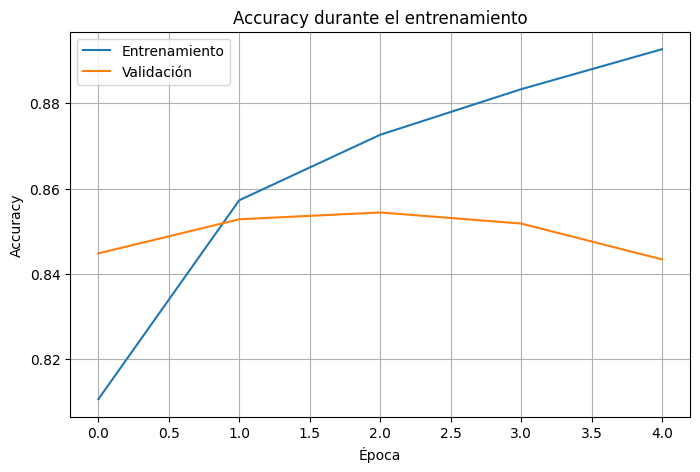

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validación"
)

plt.title("Accuracy durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

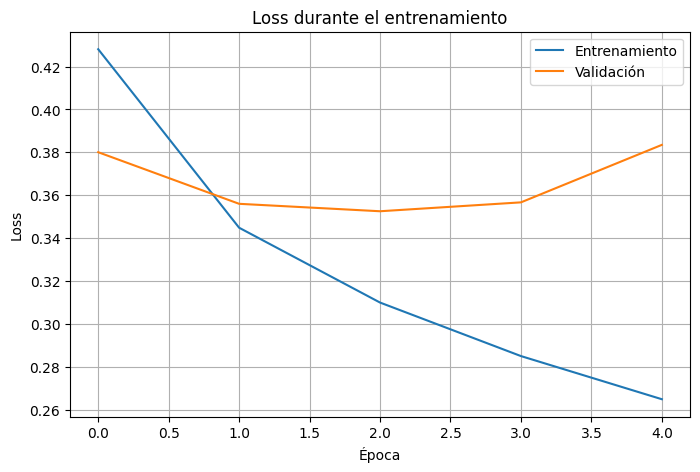

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    history.history["val_loss"],
    label="Validación"
)

plt.title("Loss durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [48]:
# ============================================
# 10 PREDICCIONES DEL CONJUNTO DE PRUEBA
# ============================================

# Seleccionar 10 reseñas del conjunto de prueba
muestras = df_test.sample(
    n=10,
    random_state=42
).copy()

# Obtener las secuencias correspondientes
X_muestras_seq = tokenizer.texts_to_sequences(
    muestras["text_clean"]
)

X_muestras_pad = pad_sequences(
    X_muestras_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Obtener probabilidades
probabilidades = modelo_final.predict(
    X_muestras_pad,
    verbose=0
).flatten()

# Convertir a clase
predicciones = (probabilidades >= 0.5).astype(int)

# Convertir números a texto
muestras["Sentimiento real"] = muestras["sentiment"].map({
    0: "Negativo",
    1: "Positivo"
})

muestras["Predicción"] = predicciones
muestras["Predicción"] = muestras["Predicción"].map({
    0: "Negativo",
    1: "Positivo"
})

muestras["Confianza"] = probabilidades

# Mostrar resultados
for i, (_, fila) in enumerate(muestras.iterrows(), start=1):

    confianza = (
        fila["Confianza"]
        if fila["Predicción"] == "Positivo"
        else 1 - fila["Confianza"]
    )

    print("=" * 100)
    print(f"PREDICCIÓN {i}")
    print("=" * 100)
    print(f"Reseña: {fila['text']}")
    print(f"Sentimiento real: {fila['Sentimiento real']}")
    print(f"Predicción: {fila['Predicción']}")
    print(f"Confianza: {confianza * 100:.2f}%")

PREDICCIÓN 1
Reseña: Las bolsas que se venden de 120 litros, que se suponen que van bien al cubo. Ni por asomo. La boca del cubo es mucho más grande que las bolsas. Cubo correcto de precio. Bolsas carísimas i no sirven.
Sentimiento real: Negativo
Predicción: Negativo
Confianza: 98.39%
PREDICCIÓN 2
Reseña: Dicen claramente en la oferta que son dos unidades. A mi me han traído una. Si sólo se envía una deberían rectificar la oferta.
Sentimiento real: Negativo
Predicción: Negativo
Confianza: 90.94%
PREDICCIÓN 3
Reseña: Traía 2 protectores en un sobre de carta postal. Podrían asegurarlos más porque se podrían romper. Las medidas no son muy exactas pero por el precio que tiene y siendo dos... Esta bien
Sentimiento real: Negativo
Predicción: Negativo
Confianza: 65.37%
PREDICCIÓN 4
Reseña: Después de parecer que la pantalla estaba perfecta y sin ninguna burbuja a la semana, se ha despegado por la parte interior de uno de los laterales. Descontento.
Sentimiento real: Negativo
Predicción: Negat

Análisis de las predicciones: Se realizaron 10 predicciones utilizando reseñas pertenecientes al conjunto de prueba. El modelo clasificó correctamente 9 de las 10 muestras seleccionadas, obteniendo un 90% de acierto en esta muestra. La única predicción incorrecta correspondió a una reseña que contenía expresiones inicialmente positivas, pero que posteriormente describía problemas con el producto. Este caso evidencia que el modelo puede presentar dificultades al interpretar opiniones con sentimientos mixtos. En términos generales, las predicciones muestran un comportamiento consistente con las métricas obtenidas durante la evaluación, donde el modelo alcanzó un accuracy del 85% sobre las 5.000 reseñas del conjunto de prueba.

In [49]:
import json
import os

# Crear carpeta models si no existe
os.makedirs("../models", exist_ok=True)

# Guardar el modelo LSTM
modelo_final.save("../models/modelo_sentimientos_lstm_es.keras")

# Guardar el tokenizer
with open("../models/tokenizer_es.json", "w", encoding="utf-8") as archivo:
    archivo.write(tokenizer.to_json())

print("✅ Modelo guardado correctamente.")
print("✅ Tokenizer guardado correctamente.")

✅ Modelo guardado correctamente.
✅ Tokenizer guardado correctamente.


In [50]:
from google.colab import files

files.download("../models/modelo_sentimientos_lstm_es.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
files.download("../models/tokenizer_es.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>